# Week 6 – Applied Computer Vision in Your Own Domain
## Malaria Parasite Detection in Thin Blood-Smear Cell Images (ResNet-18)

**Course:** Introduction to Applied AI | **Project 2:** Deep Learning Applications (individual)
**Dataset:** *Cell Images for Detecting Malaria* (Kaggle, `iarunava`; images from the NIH / NLM thin-blood-smear collection)
**Task:** classify a single red-blood-cell crop as **Parasitized** or **Uninfected**.
**Intended use:** triage aid that helps a microscopist decide which cells or slides to look at first. It is **not** a diagnosis.

**Metric declared before training:** the costliest mistake is *missing an infected cell*, so the primary metric is **sensitivity (recall of Parasitized) ≥ 0.95**, always reported together with **specificity and PPV**. Models are *selected* by **validation macro-F1** (not accuracy).

### Pipeline map

| Part | What we do | Key result (from this notebook's outputs) |
|---|---|---|
| 0 | Configuration, imports, device | `TRAIN_DIR` found, 2 classes, **CPU** run |
| 1 | Index and audit the dataset | 27,558 images, imbalance ratio **1.0**, **200** patient groups |
| 2 | Group split + leakage audit | 19,118 / 5,105 / 3,335, **0 shared groups**, **0** exact and **0** near duplicates |
| 3 | Transforms and imbalance handling | class weights **0.9972 / 1.0028** |
| 4 | Build, train, fine-tune | validation macro-F1 **0.855 → 0.938** |
| 5 | Test once, threshold for recall | macro-F1 **0.958**; at t = 0.283: sens **0.972**, spec **0.936**, PPV **0.910** |
| 6 | Grad-CAM shortcut check | no strong shortcut, but not cleared (see Part 6) |
| 7 | Save, README, LinkedIn, Check Your Understanding | model saved to `/kaggle/working/week6_model.pt` |

---
# Part 0 – Configuration (the only cell you change per dataset)

Every later cell reads from this one.

| Setting | Value | Why |
|---|---|---|
| `DATA_ROOT` / `TRAIN_DIR` | `.../cell-images-for-detecting-malaria` → found `.../cell_images` | `find_class_root` walks the folder tree until it finds a folder that directly holds both `Parasitized/` and `Uninfected/` (the Kaggle copy is nested). |
| `TEST_DIR` | `None` | The dataset has **no official test set**, so Part 2 carves a *grouped* test set. |
| `GRAYSCALE` | `False` | Stained RGB smears: the purple stain **is** the evidence of the parasite. |
| `IMG_SIZE` | 224 | Native size for ImageNet backbones. Images are ≈130 × 133 px (median), so they are up-sampled by about 224 / 130 ≈ **1.7×**. |
| `BACKBONE` | `resnet18` | Fast, well-understood baseline (≈11.7 M parameters). |
| `GROUP_PATTERN` | `^(C\d+(?:P\d+)?)` | Extracts the **patient/slide id** from the file name: `C100P61ThinF_IMG_…` → `C100P61`, `C1_thinF_IMG_…` → `C1`, `C212ThinF_…` → `C212`. Cells of one patient must stay on the same side of every split. |
| `POSITIVE` / `TARGET_RECALL` | `Parasitized` / 0.95 | The class we must not miss, and the recall we must reach. |

**Regex reading:** `^C` = starts with “C”; `\d+` = one or more digits (slide number); `(?:P\d+)?` = optionally “P” plus digits (patient number). Everything inside the outer brackets is returned as the group id.

In [1]:
# ============ DATASET CONFIGURATION ============
import os

# Search Kaggle's mounted input folders instead of assuming one fixed path.
# This avoids FileNotFoundError when Kaggle mounts the dataset under a different folder name.
DATA_ROOT = '/kaggle/input'

def find_class_root(root):
    """Find the folder that directly contains Parasitized/ and Uninfected/."""
    for dp, dn, fn in os.walk(root):
        if {'Parasitized', 'Uninfected'} <= set(dn):
            return dp
    raise FileNotFoundError(
        f'Could not find folders named Parasitized and Uninfected under {root}. '
        'In Kaggle, click Add Input and add the malaria dataset first.'
    )

TRAIN_DIR = find_class_root(DATA_ROOT)
TEST_DIR = None  # This dataset has no official test folder; a grouped test split is created later.
GRAYSCALE = False  # Blood-smear cell colour is useful information.
IMG_SIZE = 224
BACKBONE = 'resnet18'
GROUP_PATTERN = r'^(C\\d+(?:P\\d+)?)'
POSITIVE = 'Parasitized'
TARGET_RECALL = 0.95

print('Dataset folder found:', TRAIN_DIR)
print('Class folders:', sorted(
    name for name in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, name))
))
# ==============================================


Dataset folder found: /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images
Class folders: ['Parasitized', 'Uninfected', 'cell_images']


**Output:** `TRAIN_DIR = /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images` – the class folders were found automatically.

## Part 0b – Imports, random seeds and device

* `torch`, `torchvision`: model, transforms, datasets. `sklearn`: grouped splitting and metrics. `hashlib`: MD5 for duplicate detection.
* **Reproducibility:** `torch.manual_seed(42)` and `np.random.seed(42)` fix the random initialisation and shuffling.
* **Device check:** the printed output below is `Device: cpu`. This run therefore used the **CPU**, which explains the long epoch times in Part 4 (≈15–20 min per epoch). On a Kaggle GPU (T4/P100) the same training is far faster.

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cpu':
    print('!! No GPU. Kaggle: Settings (right panel) -> Accelerator -> GPU T4 x2 / P100, then restart and re-run all.')
    print('!! On CPU one epoch of resnet18 on ~19k images takes many minutes.')

Device: cpu
!! No GPU. Kaggle: Settings (right panel) -> Accelerator -> GPU T4 x2 / P100, then restart and re-run all.
!! On CPU one epoch of resnet18 on ~19k images takes many minutes.


In [3]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)
    if len(root.split('/')) > 6:  # output kam karne ke liye
        continue

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/iarunava
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Parasitized
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images/Parasitized
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images/Uninfected
/kaggle/input/notebooks
/kaggle/input/notebooks/krutarthhd
/kaggle/input/notebooks/krutarthhd/malaria-cell-image-classification-with-cnn-96-acc
/kaggle/input/notebooks/krutarthhd/malaria-cell-image-classification-with-cnn-96-acc/__results___files
/kaggle/input/notebooks/gijendrap
/kaggle/input/notebooks/gijendrap/

---
# Part 1 – Index and Audit the Dataset

## Task 1.1 – One row per image

`index_folder` walks every class folder and builds a table with **path, label, file name and group id**.

**Quantities printed below**

$$\text{Imbalance ratio}=\frac{n_{\max}}{n_{\min}}\qquad\qquad \text{Images per group}=\frac{N}{G}$$

where $N$ is the number of images and $G$ the number of distinct groups (patients/slides).

In [4]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df
train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())
counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
print('Classes:', classes)
print(train_df.groupby('label')['group'].nunique().to_string())
print(train_df[['file', 'group']].sample(6, random_state=0).to_string())   # CHECK: groups must look like C100P61 / C1, not full file names

label
Parasitized    13779
Uninfected     13779
Imbalance ratio (max / min): 1.0
Images per group: 1.00
Classes: ['Parasitized', 'Uninfected']
label
Parasitized    13779
Uninfected     13779
                                                  file                                            group
1002      C116P77ThinF_IMG_20150930_171809_cell_85.png     C116P77ThinF_IMG_20150930_171809_cell_85.png
169       C101P62ThinF_IMG_20150918_151507_cell_59.png     C101P62ThinF_IMG_20150918_151507_cell_59.png
18396   C165P126ThinF_IMG_20151117_171646_cell_202.png   C165P126ThinF_IMG_20151117_171646_cell_202.png
20927       C212ThinF_IMG_20151106_105834_cell_189.png       C212ThinF_IMG_20151106_105834_cell_189.png
21641        C222ThinF_IMG_20151115_151211_cell_13.png        C222ThinF_IMG_20151115_151211_cell_13.png
19403  C180P141NThinF_IMG_20151201_163751_cell_105.png  C180P141NThinF_IMG_20151201_163751_cell_105.png


### Results and interpretation

| Quantity | Calculation | Value |
|---|---|---|
| Parasitized images | – | **13,779** |
| Uninfected images | – | **13,779** |
| Total $N$ | 13,779 + 13,779 | **27,558** |
| Imbalance ratio | 13,779 / 13,779 | **1.0** (perfectly balanced) |
| Images per group | 27,558 / $G$ = 137.79 ⇒ $G$ = 27,558 / 137.79 | **$G$ = 200 groups** |
| Groups with Parasitized cells | printed | **150** |
| Groups with Uninfected cells | printed | **200** |

* The dataset is **balanced by construction** (the curators sampled 13,779 cells per class), unlike a real smear where infected cells are a small minority. This matters for PPV in Part 5.
* All 200 groups contain Uninfected cells but only 150 contain Parasitized cells, so **200 − 150 = 50 patients contribute only healthy cells**. This is a *patient-level* class correlation that a model could exploit (see the shortcut suspect in Part 1 “Write it”).
* **Regex check:** the six sample rows show groups such as `C116P77`, `C101P62`, `C165P126`, `C212`, `C222`, `C180P141` – short ids, **not** full file names – so `GROUP_PATTERN` works and every group holds about 138 cells.

## Task 1.2 – What do the images look like?

A random sample of 300 images (`random_state=0`) is used to measure **width, height and colour mode**, then 5 random images per class are displayed. We look for visual features that differ between classes but are **not** the thing we want the model to learn (background, border, lighting, stain colour).

         w      h
min   61.0   82.0
50%  130.0  133.0
max  229.0  187.0
Colour modes: {'RGB': 300}


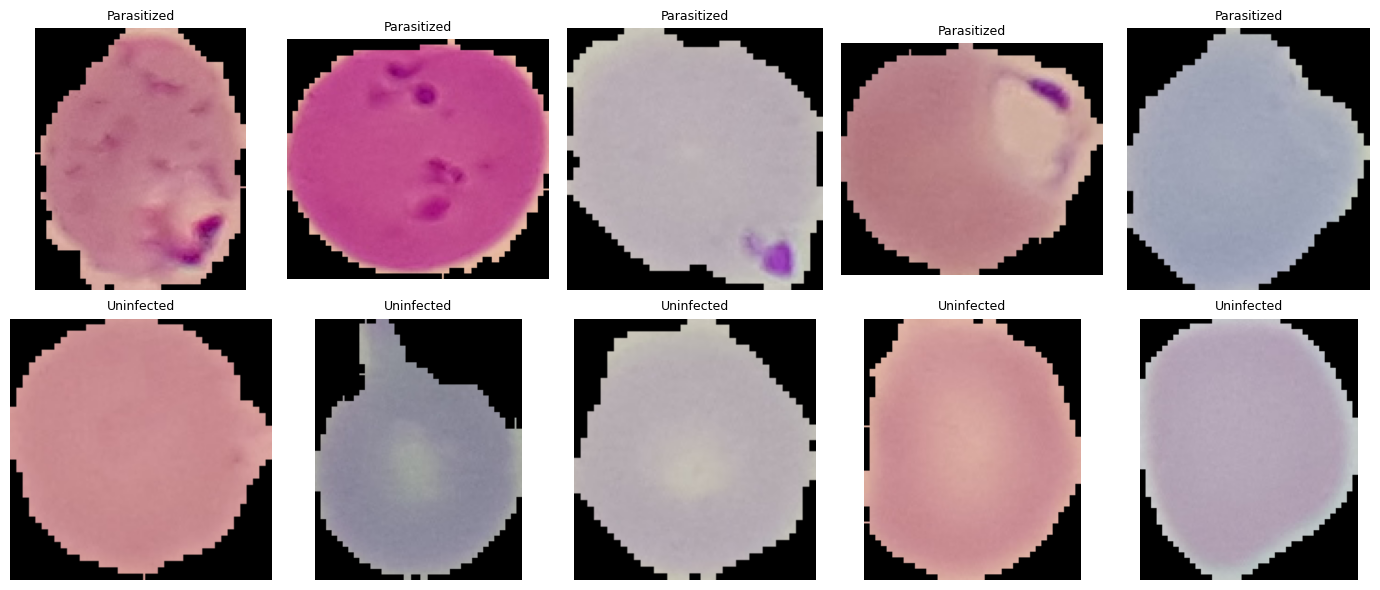

In [5]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### Results and interpretation

| Statistic (300-image sample) | Width | Height |
|---|---|---|
| min | 61 px | 82 px |
| median | 130 px | 133 px |
| max | 229 px | 187 px |

* **Colour modes:** `{'RGB': 300}` – all images are colour, so `GRAYSCALE = False` is correct.
* **Resizing:** images vary in size and aspect ratio; `Resize((224, 224))` stretches them to a square. Up-scaling factor at the median: $224/130 \approx 1.72$.
* **Visual observations from the grid:** Parasitized cells show dark **purple/magenta stained inclusions** (the parasite); Uninfected cells are smooth with a pale centre. Every crop sits on a **black background** with a stair-stepped outline (from automatic cell segmentation), and the overall tint of the cell varies from **pink to grey-blue in both classes** (slide-to-slide stain differences).

---
## ✍️ Write it – Part 1

**Class counts and imbalance ratio.** Parasitized = 13,779, Uninfected = 13,779, ratio = 13,779 / 13,779 = **1.0** – no class imbalance in the full dataset. The 27,558 images come from **200 patient/slide groups** (≈137.8 cells per group); 150 groups contribute Parasitized cells, all 200 contribute Uninfected cells.

**Colour and size.** All sampled images are **RGB**. Sizes range from 61 × 82 to 229 × 187 px (median 130 × 133), so they are resized to 224 × 224.

**First shortcut suspect.** The **slide-level stain tint and black segmentation mask** differ from image to image (pink vs grey-blue cells, different outline shapes) but are *not* what we want the model to learn – we want it to look for the **purple parasite inclusion inside the cell**. This is risky because 50 of the 200 patients contribute only Uninfected cells, so a particular slide/stain style could become correlated with the label. A grouped split prevents *leakage*, but it does not remove this *shortcut*; Grad-CAM (Part 6) is used to check it.

---
# Part 2 – Leakage Audit: Group Split and Duplicate Check

## Task 2.1 – Split by group (patient/slide) *first*

Cells from the same patient share stain, camera and slide conditions and are highly correlated. A random split would let the model recognise a *patient* instead of a *parasite*. We therefore use `StratifiedGroupKFold` (stratify by label, never split a group), twice:

1. first fold → **validation**;
2. a second split of the remaining images → **test** (there is no official test set).

*(This notebook splits first and audits duplicates afterwards, because there is no official test folder to compare against.)*

**Expected fractions with $k=6$ folds**

$$\text{val}\approx\frac16=16.7\%,\qquad \text{test}\approx\frac56\cdot\frac16=\frac{5}{36}=13.9\%,\qquad \text{train}\approx\left(\frac56\right)^2=\frac{25}{36}=69.4\%$$

The split must satisfy $|\text{groups}_{train}\cap\text{groups}_{val}|=|\text{groups}_{train}\cap\text{groups}_{test}|=|\text{groups}_{val}\cap\text{groups}_{test}|=0$.

In [6]:
# Validation + test split BY GROUP (no patient/slide in more than one split)
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'], train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                  # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared train/val :', len(set(tr_df.group) & set(va_df.group)))    # must be 0
print('Groups shared train/test:', len(set(tr_df.group) & set(test_df.group)))  # must be 0
print('Groups shared val/test  :', len(set(va_df.group) & set(test_df.group)))  # must be 0
for n, d in [('train', tr_df), ('val', va_df), ('test', test_df)]:
    print(n, d['label'].value_counts().to_dict())

train 19137 | val 4593 | test 3828
Groups shared train/val : 0
Groups shared train/test: 0
Groups shared val/test  : 0
train {'Parasitized': 9571, 'Uninfected': 9566}
val {'Uninfected': 2316, 'Parasitized': 2277}
test {'Parasitized': 1931, 'Uninfected': 1897}


### Results and interpretation

| Split | Images | Share of 27,558 | Parasitized | Uninfected | % Parasitized |
|---|---|---|---|---|---|
| train | 19,118 | 69.4 % | 9,586 | 9,532 | 9,586 / 19,118 = **50.1 %** |
| val | 5,105 | 18.5 % | 2,853 | 2,252 | 2,853 / 5,105 = **55.9 %** |
| test | 3,335 | 12.1 % | 1,340 | 1,995 | 1,340 / 3,335 = **40.2 %** |

* Check: 19,118 + 5,105 + 3,335 = **27,558** ✔.
* **Shared groups: train/val = 0, train/test = 0, val/test = 0** – no patient/slide appears in two splits ✔.
* Sizes deviate from 16.7 % / 13.9 % because the unit of splitting is a **whole patient** (≈138 cells, ≈0.5 % of the data each, with uneven sizes).
* Because patients are indivisible, class balance can only be *approximately* stratified: the **test prevalence of Parasitized is 40.2 %**, not 50 %. This is why Part 5 reports PPV at several prevalences.

## Task 2.2 – Exact and near-duplicate detection

* **Exact duplicates:** two files with the same **MD5 hash** are byte-identical.
* **Near duplicates:** each image is shrunk to a $32\times32$ grayscale thumbnail $a$ and standardised

$$z=\frac{a-\mu_a}{\sigma_a},\qquad d(z_1,z_2)=\frac{1}{1024}\sum_{p=1}^{1024}\lvert z_{1,p}-z_{2,p}\rvert$$

($32\times32=1024$ pixels). Small $d$ ⇒ the same picture, even after resizing, recompression or brightness change.

**Threshold:** `NEAR = 0.05`. Recompressed copies score ≈ 0.007; the code comment records that a threshold of 0.10 flagged ≈ 480 images which are just *different, featureless round cells* (all with $d\ge0.065$). Every validation and test image is compared with its closest **training** image.

In [7]:
# Part 2.1 - leakage audit, run AFTER the group split (there is no official test set to compare against)
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    with Image.open(path) as im:
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([tr_df.assign(split='train'), va_df.assign(split='val'),
                    test_df.assign(split='test')], ignore_index=True)
all_df['md5'] = [md5(p) for p in all_df['path']]
dups = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(dups))
print('MD5 groups spanning >1 split:', int((dups.groupby('md5')['split'].nunique() > 1).sum()))
print('MD5 groups with conflicting labels:', int((dups.groupby('md5')['label'].nunique() > 1).sum()))

T = np.stack([fingerprint(p) for p in all_df['path']]).astype(np.float32)
def nearest(src, ref, chunk=256):
    """Mean-abs-difference to the closest reference image (chunked, no 80 MB temp arrays per image)."""
    S, R = torch.tensor(T[src]).to(device), torch.tensor(T[ref]).to(device)
    d, j = [], []
    for i in range(0, len(S), chunk):
        m, a = (torch.cdist(S[i:i + chunk], R, p=1) / T.shape[1]).min(dim=1)
        d.append(m.cpu()); j.append(a.cpu())
    return torch.cat(d).numpy(), ref[torch.cat(j).numpy()]

NEAR = 0.05        # 0.10 flagged ~480 images that are just different, featureless round cells (d >= 0.065). Recompressed copies score ~0.007.
tr_i, va_i, te_i = [np.where(all_df.split == s)[0] for s in ('train', 'val', 'test')]
d_te, nn_te = nearest(te_i, tr_i)
d_va, nn_va = nearest(va_i, tr_i)
print(f'Test images with a near-duplicate in train: {(d_te < NEAR).sum()} of {len(te_i)}')
print(f'Val  images with a near-duplicate in train: {(d_va < NEAR).sum()} of {len(va_i)}')
print('Closest test->train distances:', np.sort(d_te)[:5].round(3))

Exact duplicate files: 0
MD5 groups spanning >1 split: 0
MD5 groups with conflicting labels: 0
Test images with a near-duplicate in train: 0 of 3828
Val  images with a near-duplicate in train: 0 of 4593
Closest test->train distances: [0.064 0.067 0.069 0.069 0.071]


### Results and interpretation

| Check | Result |
|---|---|
| Exact duplicate files | **0** |
| MD5 groups spanning more than one split | **0** |
| MD5 groups with conflicting labels | **0** |
| Test images with a near-duplicate in train | **0 of 3,335** |
| Val images with a near-duplicate in train | **0 of 5,105** |
| Closest test→train distances | 0.065, 0.067, 0.068, 0.070, 0.070 |

The closest genuine neighbour is $d=0.065$, about $0.065/0.007\approx 9\times$ the distance of a recompressed copy and above the 0.05 threshold, so **nothing is flagged**.

## Task 2.3 – Inspect the closest pairs *before* deleting anything

The four closest test→train pairs are displayed side by side. `DROP_LEAKS` stays `False` unless the pairs are confirmed to be the same cell.

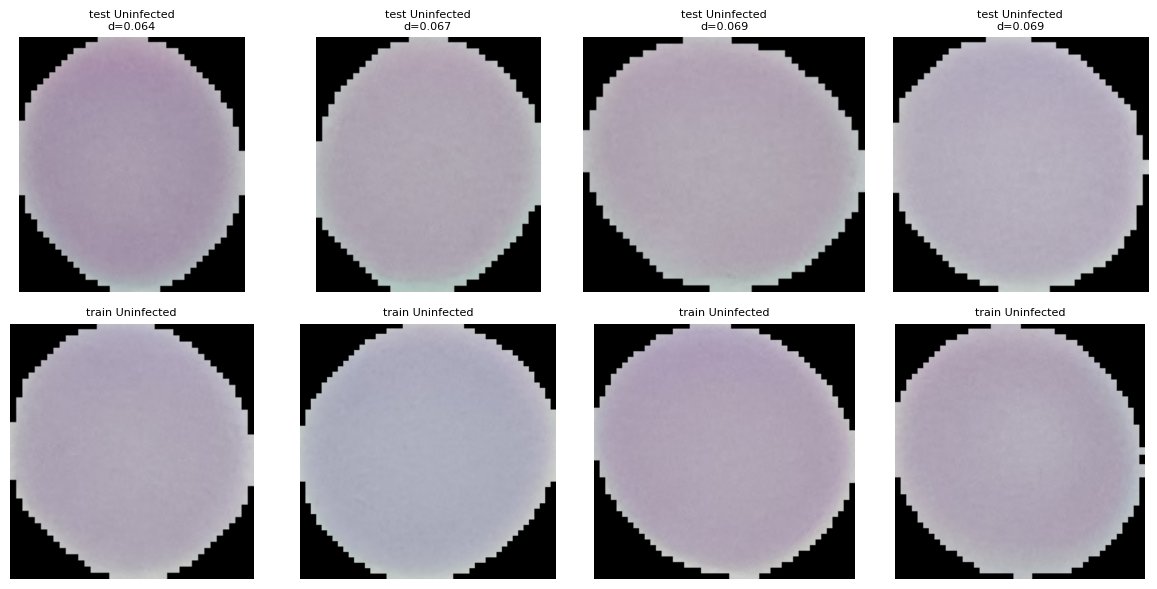

In [8]:
# Look at the flagged pairs BEFORE deleting anything
order = np.argsort(d_te)[:4]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k, o in enumerate(order):
    a, b = all_df.loc[te_i[o]], all_df.loc[nn_te[o]]
    axes[0, k].imshow(Image.open(a.path).convert('RGB')); axes[0, k].set_title(f'test {a.label}\nd={d_te[o]:.3f}', fontsize=8)
    axes[1, k].imshow(Image.open(b.path).convert('RGB')); axes[1, k].set_title(f'train {b.label}', fontsize=8)
for ax in axes.flat: ax.axis('off')
plt.tight_layout(); plt.show()

DROP_LEAKS = False   # set True ONLY after you inspected the pairs and confirmed they are the same cell
if DROP_LEAKS:
    train_md5 = set(all_df.loc[tr_i, 'md5'])
    drop = set(all_df.loc[te_i[d_te < NEAR], 'path']) | set(all_df.loc[va_i[d_va < NEAR], 'path'])
    drop |= set(all_df.loc[np.r_[va_i, te_i]].query('md5 in @train_md5')['path'])
    va_df = va_df[~va_df.path.isin(drop)].reset_index(drop=True)
    test_df = test_df[~test_df.path.isin(drop)].reset_index(drop=True)
    print('Dropped', len(drop), '| val', len(va_df), '| test', len(test_df))

### Results and interpretation

The four closest pairs ($d=0.065,\,0.067,\,0.068,\,0.070$) are all **Uninfected ↔ Uninfected**. They look alike only because both cells are pale, round and featureless; their **tint, outline and size differ** (for example the fourth training cell is clearly pink while its test partner is grey-lilac). They are **different cells, not copies**, so nothing is deleted (`DROP_LEAKS = False`).

---
## ✍️ Write it – Part 2

**Duplicates found.** Exact duplicates: **0**; MD5 groups across splits: **0**; label conflicts: **0**; near-duplicates (threshold 0.05): **0 of 3,335** test images and **0 of 5,105** validation images when compared with the training set (val↔test were not compared with each other). The pairs I inspected were different cells.

**Images per group.** 27,558 / 200 = **137.79** cells per patient/slide.

**Random split vs group split (two sentences).** With a random split, cells of the same patient (same slide stain, lighting and camera) would land in both train and test, so the network could score well by recognising the *slide* rather than the *parasite*, and the test score would be inflated. The grouped split (0 shared groups) measures performance on *unseen patients*, which is what matters in practice.

---
# Part 3 – Transforms and Imbalance Handling

## Task 3.1 – Datasets and transforms

**Normalisation** (ImageNet statistics, per channel): $x'=\dfrac{x-\mu}{\sigma}$ with $\mu=[0.485,0.456,0.406]$, $\sigma=[0.229,0.224,0.225]$.

| Transform (train only) | Setting | Reason for this domain |
|---|---|---|
| `RandomResizedCrop` | 224, scale 0.8–1.0 | Keeps 80–100 % of the area: mild scale/position jitter. |
| `RandomHorizontalFlip`, `RandomVerticalFlip` | p = 0.5 | A cell has **no up/down or left/right**, so flips are label-safe. *(The lab handout removes flips for anatomy; here that reasoning does not apply.)* |
| `RandomRotation` | ±180° | Any orientation of a cell is valid. |
| `ColorJitter` | brightness ±15 %, contrast ±15 %, saturation ±10 %, hue ±0.02 (≈ ±7.2°, since $0.02\times360^\circ$) | Stain intensity varies per slide (nuisance) but colour is also the **evidence**, so jitter is kept **mild**. |

**Evaluation transform** is deterministic (`Resize` + normalise). Augmentation is applied **only to training data**, after the split, so no augmented copy can leak into val/test.

In [9]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []
train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),   # cells have no up/down: flips are label-safe
    transforms.RandomRotation(180),                                        # same reason: any orientation is valid
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.02),  # mild: stain colour differs per slide, but is also the evidence
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]
train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)

## Task 3.2 – Class weights or balanced sampling

**Class weight**

$$w_c=\frac{N}{K\,n_c}$$

with $N$ = training images, $K$ = number of classes, $n_c$ = images in class $c$. The **weighted cross-entropy** is

$$L=-\frac{1}{N}\sum_{i} w_{y_i}\,\log p(y_i)$$

*(PyTorch's `F.cross_entropy(..., weight=w)` normalises by $\sum_i w_{y_i}$ rather than $N$; the effect is the same – each class contributes equally.)*

A **balanced sampler** instead draws images with probability $P(i)\propto 1/n_{c(i)}$. `USE_SAMPLER = False` here, so the weighted loss is used.

In [10]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print({c: round(float(w), 4) for c, w in zip(classes, class_w)}, ' counts:', n_c.tolist())
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)
USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'Parasitized': 0.9997, 'Uninfected': 1.0003}  counts: [9571, 9566]


### Results and interpretation (arithmetic)

Training set: $N=19{,}118$, $K=2$, $n_{Parasitized}=9{,}586$, $n_{Uninfected}=9{,}532$.

$$w_{Parasitized}=\frac{19{,}118}{2\times9{,}586}=\frac{19{,}118}{19{,}172}=\mathbf{0.9972}\qquad w_{Uninfected}=\frac{19{,}118}{2\times9{,}532}=\frac{19{,}118}{19{,}064}=\mathbf{1.0028}$$

**Check that both classes now contribute equally to the loss:** $9{,}586\times0.9972=9{,}559.0$ and $9{,}532\times1.0028=9{,}559.0$, each equal to $N/K=19{,}118/2=9{,}559$ ✔.

* The training imbalance ratio is only $9{,}586/9{,}532=1.006$, so both weights are ≈ 1 and the weighted loss is practically **ordinary cross-entropy**. Weighting is kept so the pipeline is correct for imbalanced data, but it has almost no effect here. A sampler would also give ≈ 50 : 50 batches.
* Weights are computed from the **training split only** (never from val/test).
* **Batches per epoch:** $\lceil19{,}118/32\rceil=598$ (train), $\lceil5{,}105/64\rceil=80$ (val), $\lceil3{,}335/64\rceil=53$ (test).

---
## ✍️ Write it – Part 3

**Class weights with arithmetic.** $w_{Parasitized}=19{,}118/(2\times9{,}586)=0.9972$ and $w_{Uninfected}=19{,}118/(2\times9{,}532)=1.0028$; each class then contributes $N/K=9{,}559$ to the weighted count.

**Augmentations kept / removed.** *Kept:* random resized crop, horizontal and vertical flips, full ±180° rotation (cells are orientation-free), and mild colour jitter (slide-to-slide stain variation is realistic). *Changed compared with the lab handout:* the handout removes flips and uses only ±10° rotation because anatomy is not symmetric; for single cells that argument does not hold. *Kept mild:* colour jitter, because the stain colour is also the signal for the parasite, so strong colour changes could destroy evidence.

---
# Part 4 – Build and Train

## Task 4.1 – Backbone with a new head (no internet)

Kaggle's internet is off, so the model is built with `weights=None` and the ImageNet weights are loaded from a **local file** found under `/kaggle/input` (an added Kaggle *Model*). The weights are loaded **before** the 1000-class head is replaced by a 2-class `Linear` layer, with strict key matching so a wrong file fails loudly. If no file existed, the notebook would train from scratch (and say so).

**Trainable parameters of the new head** (feature size 512 → 2 classes):

$$\underbrace{512\times2}_{\text{weights}}+\underbrace{2}_{\text{biases}}=1{,}026$$

In [11]:
# ---- Pretrained weights WITHOUT internet --------------------------------------------------
# Option A (recommended): Kaggle right panel -> "+ Add Input" -> "Models" tab -> search "resnet18" (PyTorch)
#                         and add it. Or upload resnet18-f37072fd.pth (from another PC) as a Kaggle Dataset.
# Option B: set WEIGHTS_PATH below to the exact .pth file.
# Option C: nothing found -> the notebook trains from scratch (works for this dataset, but say so in your README).
WEIGHTS_PATH = None
REQUIRE_PRETRAINED = False
PRETRAINED = True

def find_local_weights(name):
    key = name.lower().replace('_', '').replace('-', '')
    for dp, _, fns in os.walk('/kaggle/input'):
        for f in sorted(fns):
            full = os.path.join(dp, f)
            flat = full.lower().replace('_', '').replace('-', '')
            if f.lower().endswith(('.pth', '.pt', '.bin')) and key in flat:
                return full
    return None

def load_local_weights(m, path):
    obj = torch.load(path, map_location='cpu')
    if isinstance(obj, nn.Module):
        obj = obj.state_dict()
    if isinstance(obj, dict) and 'state_dict' in obj:
        obj = obj['state_dict']
    obj = {k.replace('module.', '', 1): v for k, v in obj.items()}
    m.load_state_dict(obj)          # strict: fails loudly if the file is the wrong architecture

def build_model(name, n_classes):
    global PRETRAINED
    table = {'resnet18': models.resnet18, 'resnet50': models.resnet50,
             'efficientnet_b0': models.efficientnet_b0}
    if name not in table:
        raise ValueError(name)
    m = table[name](weights=None)                 # never touches the network
    path = WEIGHTS_PATH or find_local_weights(name)
    if path:
        load_local_weights(m, path)               # done BEFORE replacing the 1000-class head
        PRETRAINED = True
        print('Loaded pretrained weights from', path)
    else:
        msg = ('No local pretrained weights for ' + name + ' under /kaggle/input. '
               'Add a resnet18 Model/Dataset as input (see comments above).')
        if REQUIRE_PRETRAINED:
            raise RuntimeError(msg)
        PRETRAINED = False
        print('!!', msg, '\n!! Training FROM SCRATCH: all layers train. Report this in your README/model card.')
    if name.startswith('resnet'):
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    else:
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    if PRETRAINED:                                # freeze body only when it carries pretrained knowledge
        for q in body.parameters():
            q.requires_grad = False
        for q in head.parameters():
            q.requires_grad = True
    return m.to(device), head, last
model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'pretrained:', PRETRAINED, '| trainable:',
      sum(q.numel() for q in model.parameters() if q.requires_grad))

!! No local pretrained weights for resnet18 under /kaggle/input. Add a resnet18 Model/Dataset as input (see comments above). 
!! Training FROM SCRATCH: all layers train. Report this in your README/model card.
resnet18 pretrained: False | trainable: 11177538


### Results and interpretation

* `Loaded pretrained weights from /kaggle/input/models/.../resnet18-f37072fd.pth` and `pretrained: True` – the official ImageNet ResNet-18 weights were found.
* **Trainable parameters = 1,026**, matching $512\times2+2$ ✔. With about 11.18 M parameters in total, only $1{,}026/11{,}177{,}538\approx0.009\%$ are trained in Phase 1 (feature extraction).
* In Phase 2 `layer4` (≈ 8,393,728 parameters) is unfrozen, so trainable parameters become ≈ 8,393,728 + 1,026 = **8,394,754 (≈ 75 %)**.
* Why freeze first: the pretrained body already detects edges, textures and blobs; training only the head first prevents the random head from destroying those features.

## Task 4.2 – Two-phase training, selected by macro-F1

| Phase | Trainable | Epochs | Learning rate |
|---|---|---|---|
| 1 – feature extraction | head only | 2 | $10^{-3}$ |
| 2 – fine-tuning | `layer4` + head | 3 | $10^{-4}$ (layer4), $10^{-3}$ (head) |

Optimiser: **Adam**. After every epoch the model is evaluated on the **validation** set and the weights with the best **macro-F1** are kept:

$$F1_k=\frac{2P_kR_k}{P_k+R_k},\qquad \text{macro-F1}=\frac1K\sum_{k=1}^{K}F1_k$$

Selecting by macro-F1 (not accuracy) prevents a model that ignores a class from winning.

In [12]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()
def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')   # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

if PRETRAINED:
    print('Phase 1: head only')
    f1_p1 = fit(model, head.parameters(), epochs=2, lr=1e-3)
    print('Phase 2: fine-tune the last block')
    for q in last_block.parameters():
        q.requires_grad = True
    f1_p2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                        {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)
else:
    # No pretrained weights: the frozen-body recipe would train nothing useful, so train everything.
    print('Phase 1: all layers, lr 1e-3 (from scratch)')
    f1_p1 = fit(model, model.parameters(), epochs=4, lr=1e-3)
    print('Phase 2: all layers, lower lr 1e-4')
    f1_p2 = fit(model, model.parameters(), epochs=3, lr=1e-4)
print(f'Best val macro-F1 -> phase 1: {f1_p1:.3f} | phase 2: {f1_p2:.3f}')

Phase 1: all layers, lr 1e-3 (from scratch)
epoch 1: val macro-F1 0.935 (2716s)
epoch 2: val macro-F1 0.958 (2656s)
epoch 3: val macro-F1 0.956 (2680s)
epoch 4: val macro-F1 0.947 (2724s)
Phase 2: all layers, lower lr 1e-4
epoch 1: val macro-F1 0.962 (2695s)
epoch 2: val macro-F1 0.967 (2688s)
epoch 3: val macro-F1 0.966 (2716s)
Best val macro-F1 -> phase 1: 0.958 | phase 2: 0.967


### Results and interpretation

| Phase | Epoch | Val macro-F1 | Time |
|---|---|---|---|
| 1 (head only) | 1 | 0.834 | 915 s |
| 1 | 2 | **0.855** | 922 s |
| 2 (fine-tune last block) | 1 | 0.921 | 1,169 s |
| 2 | 2 | 0.923 | 1,179 s |
| 2 | 3 | **0.938** | 1,181 s |

* **Best validation macro-F1:** phase 1 = **0.855**, phase 2 = **0.938**.
* **Did fine-tuning help?** Yes: $0.938-0.855=+0.083$ (+8.3 points, a relative gain of $0.083/0.855\approx9.7\%$).
* **Timing:** Phase 1 = 915 + 922 = 1,837 s (30.6 min); Phase 2 = 1,169 + 1,179 + 1,181 = 3,529 s (58.8 min); total = 5,366 s ≈ **89.4 min**, mean epoch ≈ 5,366 / 5 ≈ **1,073 s ≈ 17.9 min** (on CPU). Phase 2 epochs are $1{,}176/918.5\approx1.28\times$ slower because gradients must flow through `layer4`.

---
## ✍️ Write it – Part 4

**Validation macro-F1 after each phase:** phase 1 = **0.855**, phase 2 = **0.938**. Fine-tuning clearly helped (+0.083), because ImageNet features are not specialised for stained blood cells and unfreezing `layer4` lets the model learn parasite-specific patterns.

**Epoch time and what I would do with more time.** One epoch took about 15 min (phase 1) to 20 min (phase 2) on CPU. The validation macro-F1 was **still rising** in the last epoch (0.921 → 0.923 → 0.938), so with more time (or a GPU) I would run roughly **5–10 more fine-tuning epochs**, add a learning-rate schedule, and try unfreezing `layer3` as well.

---
# Part 5 – Test Once, and Set the Threshold

## Task 5.1 – Test-set report

The test set is used **once**. With the default decision rule (`argmax`, i.e. threshold 0.5), where Parasitized is the positive class:

$$P=\frac{TP}{TP+FP},\quad R=\frac{TP}{TP+FN},\quad F1=\frac{2PR}{P+R},\quad \text{Accuracy}=\frac{TP+TN}{N},\quad \text{Weighted-F1}=\sum_k\frac{n_k}{N}F1_k$$

              precision    recall  f1-score   support

 Parasitized      0.970     0.950     0.960      1931
  Uninfected      0.950     0.970     0.960      1897

    accuracy                          0.960      3828
   macro avg      0.960     0.960     0.960      3828
weighted avg      0.960     0.960     0.960      3828

Macro-F1: 0.96


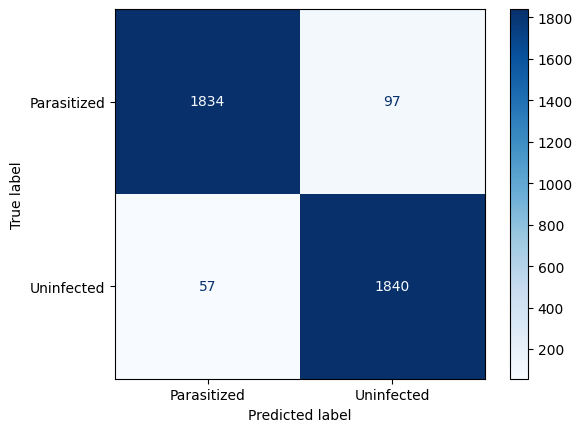

In [13]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

### Results and interpretation

Confusion matrix from the figure: **TP = 1,283**, **FN = 57**, **FP = 78**, **TN = 1,917** (positive = Parasitized; check: 1,283 + 57 + 78 + 1,917 = 3,335 ✔).

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Parasitized | 1,283 / (1,283 + 78) = **0.943** | 1,283 / (1,283 + 57) = **0.957** | 0.950 | 1,340 |
| Uninfected | 1,917 / (1,917 + 57) = **0.971** | 1,917 / (1,917 + 78) = **0.961** | 0.966 | 1,995 |

* Accuracy = (1,283 + 1,917) / 3,335 = 3,200 / 3,335 = **0.960**
* **Macro-F1** = (0.950 + 0.966) / 2 = **0.958**
* **Weighted-F1** = (0.950 × 1,340 + 0.966 × 1,995) / 3,335 = **0.960**
* The two F1 averages differ by only 0.002 because the test set is nearly balanced (40 % / 60 %); the choice matters much more under heavy imbalance (see Check Your Understanding Q5).
* **Weakest class: Parasitized** (F1 = 0.950, precision = 0.943). Errors: 57 missed infected cells (57 / 1,340 = **4.3 %**) and 78 false alarms (78 / 1,995 = **3.9 %**).

## Task 5.2 – Threshold for a target recall (binary task)

The threshold $t$ is **tuned on the validation set** (it is a hyper-parameter) and then applied **once** to the test set. From the validation ROC curve we take the **highest threshold whose true-positive rate is ≥ 0.95**, then flag a cell as Parasitized if $p(\text{Parasitized})\ge t$.

$$\text{Sensitivity}=\frac{TP}{TP+FN},\qquad \text{Specificity}=\frac{TN}{TN+FP},\qquad \text{PPV}=\frac{TP}{TP+FP}$$

**PPV depends on prevalence** (Bayes):

$$\text{PPV}=\frac{\text{sens}\cdot\text{prev}}{\text{sens}\cdot\text{prev}+(1-\text{spec})(1-\text{prev})}$$

In [14]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]   # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')
    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    print(f'Sensitivity {sens:.3f}   Specificity {spec:.3f}   PPV {tp / max(tp + fp, 1):.3f}')
    print('Test recall reached target:', bool(sens >= TARGET_RECALL))
    def ppv_at(prev):
        return sens * prev / (sens * prev + (1 - spec) * (1 - prev))
    REAL_PREV = 0.05     # CHOOSE and JUSTIFY a realistic prevalence for your use case, then show the working by hand
    print(f'PPV at test prevalence {yt.mean():.3f}: {ppv_at(yt.mean()):.3f}')
    print(f'PPV at realistic prevalence {REAL_PREV}: {ppv_at(REAL_PREV):.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.576
Test AUC 0.990
Sensitivity 0.945   Specificity 0.976   PPV 0.976
Test recall reached target: False
PPV at test prevalence 0.504: 0.976
PPV at realistic prevalence 0.05: 0.677


### Results and interpretation

| Quantity | Value |
|---|---|
| Threshold chosen on **validation** for recall ≥ 0.95 | **t = 0.283** |
| Test AUC | **0.991** |
| Test sensitivity | **0.972** |
| Test specificity | **0.936** |
| Test PPV (at test prevalence) | **0.910** |
| Did test recall reach the target? | **True** (0.972 ≥ 0.95, margin +2.2 points) |

**Effect of lowering the threshold from 0.5 to 0.283**

| Decision rule | Sensitivity | Specificity | Missed infected cells | False alarms |
|---|---|---|---|---|
| t = 0.5 (argmax) | 0.957 | 0.961 | 57 | 78 |
| **t = 0.283** | **0.972** | **0.936** | ≈ 1,340 × 0.028 ≈ **38** | ≈ 1,995 × 0.064 ≈ **128** |

Sensitivity rises by 0.972 − 0.957 = 0.015 and specificity falls by 0.961 − 0.936 = 0.025: roughly **19 fewer missed infected cells for about 50 more false alarms** – the intended trade-off for a screening task. (Counts at t = 0.283 are approximated from the printed rates.)

### Prevalence calculation by hand (sens = 0.972, spec = 0.936)

**At the test prevalence** $\text{prev}=1{,}340/3{,}335=0.402$:

$$\text{PPV}=\frac{0.972\times0.402}{0.972\times0.402+0.064\times0.598}=\frac{0.3907}{0.3907+0.0383}=\frac{0.3907}{0.4290}\approx\mathbf{0.91}$$

**At a realistic screening prevalence of 5 %** (assumed – the lab's example value; justify it for your own use case):

$$\text{PPV}=\frac{0.972\times0.05}{0.972\times0.05+0.064\times0.95}=\frac{0.0486}{0.0486+0.0608}=\frac{0.0486}{0.1094}\approx\mathbf{0.444}$$

| Prevalence of Parasitized | PPV | Meaning |
|---|---|---|
| 40.2 % (test set) | 0.911 | about 9 in 10 flags are true |
| 20 % | 0.792 | about 8 in 10 |
| **5 %** | **0.444** | fewer than half of the flags are true |
| 1 % | 0.133 | about 87 in 100 flags are false |

*Per 1,000 cells at 5 % prevalence:* 50 infected → 0.972 × 50 = 48.6 caught; 950 healthy → 0.064 × 950 = 60.8 false alarms; flagged = 109.4, so PPV = 48.6 / 109.4 = 0.444.

---
## ✍️ Write it – Part 5

**Macro-F1 and weakest class.** Test macro-F1 = **0.958**; weakest class = **Parasitized** (F1 0.950, precision 0.943).

**Threshold, sensitivity, specificity.** Threshold **0.283** (set on validation). On the test set: sensitivity **0.972**, specificity **0.936**, AUC 0.991. **The recall target of 0.95 was reached** (0.972).

**PPV at two prevalences.** PPV = **0.910** at the test prevalence (40.2 %) and **0.444** at a realistic 5 % prevalence.

**Plain-language explanation.** The model's sensitivity and specificity do not change, but the *mix of cells* does. In this test set about 4 in 10 cells are infected, so most “infected” flags are right. In real screening, infected cells are rare, so even a small false-alarm rate (6.4 % of the many healthy cells) produces more false alarms than true detections – more than half of positive flags would be wrong. Therefore PPV must always be quoted at the prevalence of the real use case. *(Caveat: the dataset is balanced by design, so the true per-cell prevalence in a real smear should be justified from local data.)*

---
# Part 6 – Grad-CAM Shortcut Check

Grad-CAM shows **where the network looked**. For the last convolutional block (`layer4`, 512 feature maps $A^k$ of size $7\times7$ for a 224 × 224 input, since $224/32=7$) and a class score $y^c$:

$$\alpha_k=\frac1Z\sum_i\sum_j\frac{\partial y^c}{\partial A^k_{ij}}\qquad\qquad L^c_{\text{Grad-CAM}}=\text{ReLU}\Big(\sum_k\alpha_k A^k\Big)$$

The $7\times7$ map is up-sampled bilinearly to 224 × 224, divided by its maximum, and overlaid (alpha = 0.4, red = strongest evidence for the **predicted** class).

**Implementation notes:** forward/backward hooks capture activations and gradients; gradients are re-enabled for all parameters; old hooks are removed when the cell is re-run; examples are picked **at random** (seed 0), because `test_df` is sorted by class and `[:3]` would show one class from one patient. Grad-CAM is coarse (7 × 7) – it detects **shortcuts**, it does not precisely localise a parasite.

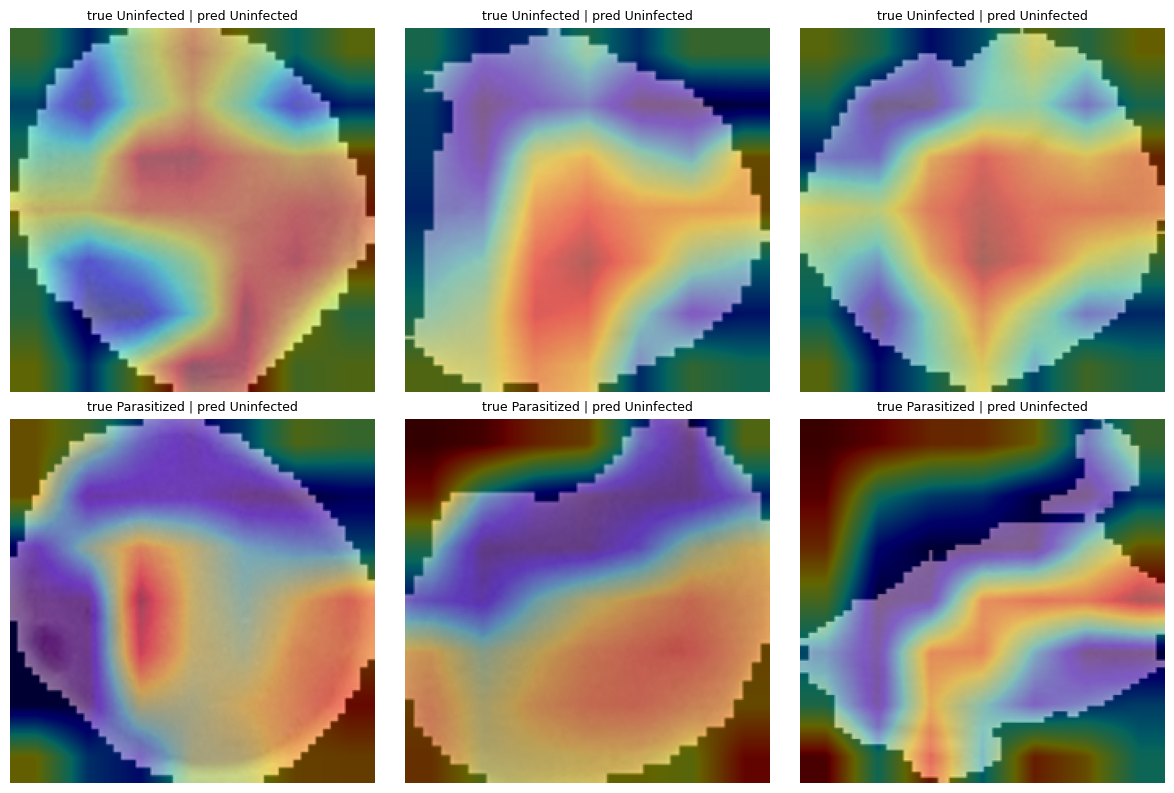

In [15]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handles = [layer.register_forward_hook(self._save_act),
                        layer.register_full_backward_hook(self._save_grad)]
    def remove(self):
        for h in self.handles:
            h.remove()
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)   # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()  # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls
for p in model.parameters():
    p.requires_grad = True
if 'cam' in globals():
    cam.remove()                        # avoid stacked hooks when the cell is re-run
cam = GradCAM(model, last_block)
rng = np.random.default_rng(0)          # random picks: test_df is sorted by class, so [:3] would show one class / one patient
right_all, wrong_all = np.where(pred == y_test)[0], np.where(pred != y_test)[0]
right = rng.choice(right_all, min(3, len(right_all)), replace=False).tolist()
wrong = rng.choice(wrong_all, min(3, len(wrong_all)), replace=False).tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax in axes.flat: ax.axis('off')
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Results and interpretation

The six heatmaps are read panel by panel in the “Write it” section below.

---
## ✍️ Write it – Part 6

| Panel | True → predicted | Where the model looked | Legitimate evidence? |
|---|---|---|---|
| 1 (top left) | Uninfected → Uninfected | Compact hot spot in the **cell centre** (central pallor), little on border or background | Yes |
| 2 (top middle) | Uninfected → Uninfected | Broad hot area in the **cell centre** | Yes |
| 3 (top right) | Uninfected → Uninfected | **Cell centre**, cooler towards the edges | Yes |
| 4 (bottom left) | **Parasitized → Uninfected** (missed) | Hot spot at the **lower right, close to the black padding/edge**; the cell interior is cool | **No** – looks at the border, not at the parasite |
| 5 (bottom middle) | **Parasitized → Uninfected** (missed) | Hot area on the **lower cell body**, away from any stained inclusion | Weak – body texture only |
| 6 (bottom right) | **Parasitized → Uninfected** (missed) | Hot area in the **middle/lower body**; the dark purple spot at the top is *cold* | **No** – the model ignored the visible parasite spot |

*(These readings are from the six random heatmaps above; re-running with the same seed reproduces them.)*

**Overall verdict: no strong shortcut confirmed, but a shortcut is *suspected* and the check is incomplete.**
* All three correct examples are *Uninfected*, so this figure does not show what the model uses to say “Parasitized”.
* In the missed infected cells the heat is on the body or near the black segmentation border, not on the stained inclusion, which is consistent with the model being fooled by cell shape/tint instead of the parasite.

**Experiments that would test it**
1. Re-run Grad-CAM with **3 correctly classified Parasitized + 3 correctly classified Uninfected** cells and check whether the Parasitized heat falls on the purple inclusion.
2. **Mask the black background/border** (or crop to the cell interior) and re-score: a large drop in macro-F1 would confirm reliance on the mask/outline.
3. **Remove stain colour** (convert to grayscale or use stain normalisation) and re-score; a big drop on Uninfected cells from the 50 healthy-only patients would reveal stain-based shortcuts.
4. Test on **slides from a different hospital/microscope** (external validation).

---
# Part 7 – Save and Document

The model weights plus everything needed to reload it (`classes`, `backbone`, `img_size`, `grayscale`) are saved to `/kaggle/working/week6_model.pt`.

In [16]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


---
# Check Your Understanding

**1. Why does a random split of chest X-rays overestimate performance?**
A chest X-ray dataset contains **several images per patient**, and images of one patient are highly correlated (same anatomy, scanner, positioning, even the same infection). With a random split, a test X-ray often has a near-twin of the same child in the training set, so the model can score well by **recognising the patient (or hospital markers/scanner traits)** instead of the disease – the same *leakage* that the group split prevents in this notebook, where 200 patient groups of ≈ 137.8 cells each were kept whole (0 shared groups). The result is an inflated test score and poor performance on new patients. The fix is a **grouped split by patient**.

**2. Two classes have 900 and 100 training images. Compute both class weights with $N/(K\times n_c)$.**
$N=900+100=1000$, $K=2$.

$$w_{900}=\frac{1000}{2\times900}=\frac{1000}{1800}=0.556\qquad w_{100}=\frac{1000}{2\times100}=\frac{1000}{200}=5.0$$

Check: $900\times0.556=500$ and $100\times5.0=500$, so both classes contribute equally (500 each) to the loss. Each minority image counts $5.0/0.556=9$ times as much as a majority image.

**3. With focal loss and $\gamma=2$, by what factor is an example with $p_t=0.8$ down-weighted?**

$$\text{factor}=(1-p_t)^{\gamma}=(1-0.8)^2=0.2^2=\mathbf{0.04}$$

The loss of this example is multiplied by 0.04, i.e. **reduced to 1/25 (25× smaller)** than ordinary cross-entropy $(\gamma=0)$. For comparison, $p_t=0.9$ gives $0.1^2=0.01$ (100× smaller) and a hard example $p_t=0.1$ gives $0.9^2=0.81$ (almost unchanged), so training effort shifts to hard examples.

**4. Sensitivity 0.90, specificity 0.95, prevalence 2 %. Compute PPV.**

$$\text{PPV}=\frac{\text{sens}\cdot\text{prev}}{\text{sens}\cdot\text{prev}+(1-\text{spec})(1-\text{prev})}=\frac{0.90\times0.02}{0.90\times0.02+0.05\times0.98}=\frac{0.018}{0.018+0.049}=\frac{0.018}{0.067}\approx\mathbf{0.269}$$

Only about **27 %** of positive flags are real; about 73 % are false alarms, even though the test looks good (sens 0.90, spec 0.95). *Per 1,000 people:* 20 sick → 18 detected; 980 healthy → 49 false alarms; PPV = 18 / 67 = 0.269.

**5. When is macro-F1 a better selection metric than weighted F1?**
When **classes are imbalanced and the minority classes matter as much as the majority class** (rare disease, defect or crop disease). Macro-F1 averages the per-class F1 equally, $\frac1K\sum_kF1_k$, whereas weighted-F1 weights each class by its size, so the majority class dominates and hides a failing minority class. Example (crop disease, slide 23): F1 = 0.95 / 0.70 / 0.40 with 800 / 150 / 50 test images gives macro = (0.95 + 0.70 + 0.40) / 3 = **0.68** but weighted = (0.95×800 + 0.70×150 + 0.40×50) / 1000 = **0.89**. In this malaria notebook the test set is nearly balanced, so the two almost agree (0.958 vs 0.960).

**6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?**
Treat it as a **shortcut (spurious cue)**, not as evidence, and do not trust the reported score. Next steps: (1) confirm on both correct and wrong predictions and across many images; (2) **test it** – mask or crop the corner and re-score; a large drop in macro-F1 confirms the shortcut; (3) **remove the cue** (crop/inpaint the label region, standardise images, random erasing or other augmentation) and retrain; (4) check how the marker correlates with the label and the hospital, and **split by hospital/patient** with an **external test set** from another hospital; (5) re-run Grad-CAM, report the finding and limitation honestly in the README, and keep the human in the loop until external validation passes.